In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide a harmless pandas warning

import pandas as pd
import wrds

conn = wrds.Connection()    # log in to WRDS (type your username and password if asked)

# Settings. If you want to change something, change it here only.
SIC        = "63"            # Insurance Carriers; Progressive is SIC 6331
FY_START   = "2021-01-01"     # we study fiscal years that END between FY_START and FY_END
FY_END     = "2024-12-31"
PULL_START = "2019-06-01"     # we pull earlier years too, because the EPS change needs last year's EPS and price
RET_START  = "2020-12-01"     # include the trading day before the first possible announcement
RET_END    = "2025-01-31"     # include the trading day after the last possible announcement
ANN_START  = pd.Timestamp("2021-01-01")
ANN_END    = pd.Timestamp("2024-12-31")
MIN_PRC    = 5                # rule: drop a company-quarter if last quarter's price is below this
MAX_CHG    = 1                # rule: drop a company-quarter if absolute SUE is above this

Loading library list...
Done


In [2]:
# ===== Step 1. Read the link file =====

# 1a. Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# 1b. gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())
link.head()

link rows: 114 | companies: 96


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,001274,71271,1987-01-30,2022-10-31,63,Y,ALLEGHANY CORP DE
1,001414,93330,2010-04-01,2099-12-31,63,PRI,PRIMERICA INC
2,001449,57904,1973-08-23,2099-12-31,63,AFL,AFLAC INC
3,001487,66800,1972-12-14,2099-12-31,63,AIG,AMERICAN INTERNATIONAL GROUP INC
4,001526,13507,1972-12-14,2022-05-31,63,ANAT,AMERICAN NATIONAL GROUP INC


In [3]:
# ===== Step 2. Pull the quarterly data =====

# 4a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 4b. Ask WRDS for only the rows and columns we need.
fq = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])

# 4c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
fq["epspxq"] = fq["epspxq"].astype("float64")
fq["prccq"]  = fq["prccq"].astype("float64")

# 4d. Check what we got.
print("company-quarters pulled from Compustat:", len(fq))
fq.head()

company-quarters pulled from Compustat: 1959


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,001274,2019-06-30,2019,2,2019-08-06,20.46,681.11
1,001414,2019-06-30,2019,2,2019-08-07,2.28,119.95
2,001449,2019-06-30,2019,2,2019-07-25,1.10,54.81
3,001487,2019-06-30,2019,2,2019-08-07,1.26,53.28
4,001526,2019-06-30,2019,2,2019-08-01,3.68,116.47


In [4]:
# ===== Step 3a. Merge 1: add permno from the link file =====
panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel))

3a. after the merge (a gvkey with 2 links is now on 2 rows): 2339


In [5]:
# ===== Step 3b. Keep only the link that was valid on the quarter-end date =====

# True/False for each row: the quarter-end date is between the start and the end of the link.
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
panel = panel[valid]

# How many rows share the same gvkey + fyearq + fqtr with another row?
n_dup = panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum()
print("3b. rows that repeat a gvkey + fyearq + fqtr before we drop them:", n_dup)

# If one company-quarter still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"])

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
r1, c1 = len(fq), fq["gvkey"].nunique()          # before the link
r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link
print("3b. company-quarters after the link merge:", r2)

3b. rows that repeat a gvkey + fyearq + fqtr before we drop them: 0
3b. company-quarters after the link merge: 1876


In [6]:
# ===== Check: does any key (gvkey + fyearq + fqtr) appear more than once? =====
# duplicated() marks a row True if an earlier row has the same gvkey, fyearq and fqtr. sum() counts the True values.
print("duplicate keys:", panel.duplicated(["gvkey", "fyearq", "fqtr"]).sum(), "(it must be 0)")

duplicate keys: 0 (it must be 0)


In [7]:
# ===== Step 5. Merge 2: add EPS four quarters ago and last quarter's price =====

# 5a. Quarter number = fiscal year * 4 + fiscal quarter. Q4 of 2021 and Q1 of 2022 are consecutive numbers.
panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]

# 5b. Copy with only the columns we need, for EPS four quarters ago.
lag4 = panel[["gvkey", "qnum", "epspxq"]].copy()

# 5c. Move every quarter forward by four: the EPS of Q1 2021 is now on the row of Q1 2022.
lag4["qnum"] = lag4["qnum"] + 4

# 5d. Give the column a new name, so that this quarter's and the old values do not mix.
lag4 = lag4.rename(columns={"epspxq": "eps_lag4"})

# 5e. Copy with only the columns we need, for last quarter's price.
lag1 = panel[["gvkey", "qnum", "prccq"]].copy()

# 5f. Move every quarter forward by one: the price of Q1 is now on the row of Q2.
lag1["qnum"] = lag1["qnum"] + 1

# 5g. Give the column a new name.
lag1 = lag1.rename(columns={"prccq": "prc_lag1"})

# 5h. Merge. how="left": keep every row of panel, even when there is no earlier quarter.
rows_before = len(panel)
panel = panel.merge(lag4, on=["gvkey", "qnum"], how="left")
panel = panel.merge(lag1, on=["gvkey", "qnum"], how="left")
print("5h. rows before and after Merge 2:", rows_before, len(panel))

# 5i. SUE: (this quarter's EPS - EPS four quarters ago) / last quarter's price.
panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

panel[["gvkey", "fyearq", "fqtr", "epspxq", "eps_lag4", "prc_lag1", "sue"]].head(8)

5h. rows before and after Merge 2: 1876 1876


,gvkey,fyearq,fqtr,epspxq,eps_lag4,prc_lag1,sue
0,001274,2019,2,20.46,NaN,NaN,NaN
1,001414,2019,2,2.28,NaN,NaN,NaN
2,001449,2019,2,1.10,NaN,NaN,NaN
3,001487,2019,2,1.26,NaN,NaN,NaN
4,001526,2019,2,3.68,NaN,NaN,NaN
5,001982,2019,2,0.11,NaN,NaN,NaN
6,002176,2019,2,5.74,NaN,NaN,NaN
7,002547,2019,2,3.73,NaN,NaN,NaN


In [8]:
# ===== Step 6. Apply the rules one at a time =====

# Start with the panel after the link merge and the two lag merges.
events = panel.copy()
r3, c3 = len(events), events["gvkey"].nunique()
print("6a. company-quarters before any rule:", r3)

# Rule 1: the announcement date must be known.
events = events[events["rdq"].notna()]
r4, c4 = len(events), events["gvkey"].nunique()
print("6b. after dropping a missing announcement date:", r4)

# Rule 2: SUE must be computable.
events = events[events["sue"].notna()]
r5, c5 = len(events), events["gvkey"].nunique()
print("6c. after dropping a missing SUE:", r5)

# Rule 3: keep announcement dates from January 2021 through December 2024.
events = events[(events["rdq"] >= ANN_START) & (events["rdq"] <= ANN_END)]
r6, c6 = len(events), events["gvkey"].nunique()
print("6d. after keeping announcements from 2021 to 2024:", r6)

# Rule 4: last quarter's stock price must be at least $5.
events = events[events["prc_lag1"] >= MIN_PRC]
r7, c7 = len(events), events["gvkey"].nunique()
print("6e. after the last-quarter price rule:", r7)

# Rule 5: the absolute value of SUE must be no greater than 1.
events = events[events["sue"].abs() <= MAX_CHG]
events = events.reset_index(drop=True)
r8, c8 = len(events), events["gvkey"].nunique()
print("6f. after the |SUE| rule:", r8)

6a. company-quarters before any rule: 1876
6b. after dropping a missing announcement date: 1846
6c. after dropping a missing SUE: 1484
6d. after keeping announcements from 2021 to 2024: 1246
6e. after the last-quarter price rule: 1157
6f. after the |SUE| rule: 1152


In [9]:
# ===== Step 7. Pull the daily returns and compute the daily abnormal return =====

# 7a. The stocks we need: the permnos of the quarters we kept after Rules 1 to 5.
permnos = ",".join(events["permno"].astype(str).unique())

# 7b. Ask WRDS for the daily stock returns and the daily market returns.
stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                         where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                     date_cols=["date"])
mkt = conn.raw_sql(f"""select date, vwretd from crsp.dsi
                       where date between '{RET_START}' and '{RET_END}'""",
                   date_cols=["date"])

# 7c. Plain numbers (a missing return becomes NaN).
stock["permno"] = stock["permno"].astype(int)
stock["ret"]    = stock["ret"].astype("float64")
mkt["vwretd"]   = mkt["vwretd"].astype("float64")

# 7d. Check the keys before merging: one row per stock-day, and one row per market day.
print("duplicate stock-days:", int(stock.duplicated(["permno", "date"]).sum()))
print("duplicate market days:", int(mkt["date"].duplicated().sum()))

# 7e. Merge 3: add the market return of the same day to every stock-day.
rows_before = len(stock)
stock = stock.merge(mkt[["date", "vwretd"]], on="date", how="left")
print("rows before and after Merge 3:", rows_before, len(stock))

# 7f. Abnormal return = stock return - market return.
stock["ar"] = stock["ret"] - stock["vwretd"]

print("stock-days:", len(stock), "| days with a missing abnormal return:", int(stock["ar"].isna().sum()))
stock.head()

duplicate stock-days: 0
duplicate market days: 0
rows before and after Merge 3: 80623 80623
stock-days: 80623 | days with a missing abnormal return: 6


,permno,date,ret,vwretd,ar
0,10239,2020-12-01,-0.015395,0.009645,-0.025040
1,10239,2020-12-02,0.005686,0.001192,0.004494
2,10239,2020-12-03,0.000000,0.002272,-0.002272
3,10239,2020-12-04,0.034629,0.010477,0.024152
4,10239,2020-12-07,-0.032787,-0.000220,-0.032567


In [10]:
# ===== Step 8. Find day 0 and add up the 3 daily abnormal returns (CAR) =====

# 8-0. Remove the columns this cell creates, in case the cell was run before.
if "td" in stock.columns:
    stock = stock.drop(columns=["td"])

for c in ["td0", "day0", "car", "days_found"]:
    if c in events.columns:
        events = events.drop(columns=[c])

# 8a. Number the trading days 1, 2, 3, ... using the market table (it has no weekends).
cal = mkt[["date"]].sort_values("date").reset_index(drop=True)
cal["td"] = cal.index + 1

# 8b. Put the trading-day number on every stock-day (same date = same number).
stock = stock.merge(cal, on="date", how="left")

# 8c. Give every announcement a number (event_id). Day 0 needs a known announcement date.
events["event_id"] = events.index
events = events[events["rdq"].notna()].sort_values("rdq")

# 8d. Day 0 = the first trading day on or after rdq. direction="forward" selects the first trading day on or after the announcement date,
#     so a Saturday announcement moves to Monday.
events = pd.merge_asof(events, cal, left_on="rdq", right_on="date", direction="forward")
events = events.rename(columns={"date": "day0", "td": "td0"})

# 8e. Merge 4: put every announcement next to ALL the days of its stock.
pairs = events[["event_id", "permno", "td0"]].merge(stock[["permno", "td", "ar"]], on="permno", how="inner")
print("8e. rows in pairs before the window:", len(pairs))

# 8f. Keep only day -1, day 0 and day +1 (trading-day number td0 - 1, td0, td0 + 1).
in_window = (pairs["td"] >= pairs["td0"] - 1) & (pairs["td"] <= pairs["td0"] + 1)
pairs = pairs[in_window]
print("8f. rows in pairs after the window:", len(pairs))

# 8g. For each announcement, add up the abnormal returns ("sum") and count the days that have one ("count").
car = pairs.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
car = car.rename(columns={"sum": "car", "count": "days_found"})

# 8h. Put the result back on the announcements. how="left" keeps an announcement even if it has no day at all.
events = events.merge(car, on="event_id", how="left")
events["days_found"] = events["days_found"].fillna(0)    # no day found = 0 days

print("how many of the 3 days were found, per announcement:")
events["days_found"].value_counts().sort_index()

8e. rows in pairs before the window: 1138711
8f. rows in pairs after the window: 3450
how many of the 3 days were found, per announcement:


days_found
0.0       2
3.0    1150
Name: count, dtype: int64

In [11]:
# ===== Step 8i. Data requirement: all 3 daily abnormal returns exist =====

# Keep only announcements where day -1, day 0 and day +1 all have an abnormal return.
events = events[events["days_found"] == 3].copy()
r9, c9 = len(events), events["gvkey"].nunique()
print("announcements left with all 3 days:", r9)

announcements left with all 3 days: 1150


In [12]:
# ===== Check 3. Look at the extreme SUE values =====

# Columns to show.
show = ["ticker", "datadate", "epspxq", "eps_lag4", "prc_lag1", "sue"]

# Sort from the smallest to the largest SUE. head(5) = first 5 rows, tail(5) = last 5 rows.
print("5 smallest SUE values:")
print(events.sort_values("sue")[show].head(5).to_string(index=False))
print()
print("5 largest SUE values:")
print(events.sort_values("sue")[show].tail(5).to_string(index=False))
print()
events["sue"].describe()

5 smallest SUE values:
ticker   datadate  epspxq  eps_lag4  prc_lag1       sue
  HALL 2023-06-30   -9.78     -3.52      6.50 -0.963077
   JXN 2022-12-31  -13.74      6.32     27.75 -0.722883
   JXN 2023-06-30   14.58     37.96     37.41 -0.624967
   MBI 2024-06-30   -5.30     -1.52      6.76 -0.559172
   JXN 2024-09-30   -6.37     33.66     74.26 -0.539052

5 largest SUE values:
ticker   datadate  epspxq  eps_lag4  prc_lag1      sue
   MBI 2024-09-30   -1.08     -3.93      5.49 0.519126
   JXN 2024-03-31   10.04    -18.11     51.20 0.549805
   LNC 2023-09-30    4.82    -10.47     25.76 0.593556
  CLVT 2023-09-30   -0.01     -6.58      9.53 0.689402
   JXN 2022-09-30   22.08      2.18     26.75 0.743925



count    1150.000000
mean        0.002710
std         0.093477
min        -0.963077
25%        -0.012441
50%         0.002346
75%         0.018897
max         0.743925
Name: sue, dtype: float64

In [13]:
# ===== The sample construction table =====
# Every row is one step. r1..r9 and c1..c9 are the counts we saved in the earlier steps.
sample_table = pd.DataFrame({
    "step": ["1. Compustat quarterly data, SIC " + str(SIC) + " (fundq)",
             "2. after the link merge (with the link dates)",
             "3. after Merge 2 (EPS four quarters ago, last quarter's price)",
             "4. announcement date is known",
             "5. SUE can be computed",
             "6. announced from January 2021 to December 2024",
             "7. last quarter's price >= $" + str(MIN_PRC),
             "8. |SUE| <= " + str(MAX_CHG),
             "9. all 3 daily abnormal returns found"],
    "rows left":      [r1, r2, r3, r4, r5, r6, r7, r8, r9],
    "companies left": [c1, c2, c3, c4, c5, c6, c7, c8, c9]
})

# Rows removed at each step = the difference from the row above. The first row removes nothing.
sample_table["rows removed"] = -sample_table["rows left"].diff()
sample_table["rows removed"] = sample_table["rows removed"].fillna(0).astype(int)

sample_table

,step,rows left,companies left,rows removed
0,"1. Compustat quarterly data, SIC 63 (fundq)",1959,92,0
1,2. after the link merge (with the link dates),1876,92,83
2,"3. after Merge 2 (EPS four quarters ago, last ...",1876,92,0
3,4. announcement date is known,1846,91,30
4,5. SUE can be computed,1484,90,362
5,6. announced from January 2021 to December 2024,1246,90,238
6,7. last quarter's price >= $5,1157,88,89
7,8. |SUE| <= 1,1152,88,5
8,9. all 3 daily abnormal returns found,1150,88,2


In [14]:
# ===== Step 10. Describe the final SUE and CAR variables =====

# Each row in events is one company-quarter announcement.
# SUE measures the earnings surprise.
# CAR measures the three-day cumulative abnormal return.

print("Final number of announcements:", len(events))
print("Final number of companies:", events["gvkey"].nunique())

# Show descriptive statistics for the two main variables.
events[["sue", "car"]].describe()

Final number of announcements: 1150
Final number of companies: 88


,sue,car
count,1150.000000,1150.000000
mean,0.002710,0.000964
std,0.093477,0.070781
min,-0.963077,-0.328115
25%,-0.012441,-0.032885
50%,0.002346,0.002746
75%,0.018897,0.032119
max,0.743925,0.469513


In [15]:
# Rank announcements by SUE and divide them into three equal-sized groups.
events["sue_group"] = pd.qcut(
    events["sue"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

# Count announcements in each SUE group.
group_counts = events.groupby("sue_group", observed=False).size()
print("Announcement count by SUE group:")
print(group_counts)

# Calculate the average CAR in each SUE group.
group_results = events.groupby("sue_group", observed=False)["car"].agg(["count", "mean"])
group_results = group_results.rename(columns={"count": "announcement_count", "mean": "average_car"})
print("Average CAR by SUE group:")
group_results

Announcement count by SUE group:
sue_group
Low       383
Middle    383
High      384
dtype: int64
Average CAR by SUE group:


,announcement_count,average_car
sue_group,,
Low,383,-0.018769
Middle,383,0.001770
High,384,0.019841


In [16]:
# ===== Final Table =====

events[["gvkey", "ticker", "datadate", "rdq", "sue", "sue_group", "car", "days_found"]].head()

,gvkey,ticker,datadate,rdq,sue,sue_group,car,days_found
0,010903,UNH,2020-12-31,2021-01-20,-0.004523,Middle,-0.009093,3.0
1,062689,TRV,2020-12-31,2021-01-21,0.016268,High,0.007019,3.0
2,014822,WRB,2020-12-31,2021-01-26,0.017334,High,-0.039774,3.0
3,064979,PPBI,2020-12-31,2021-01-26,0.000993,Middle,-0.019307,3.0
4,013341,PGR,2020-12-31,2021-01-27,0.011091,High,-0.023528,3.0


In [17]:
# ===== Check 1: Print Row Counts Before and After Every Step =====
print(f"Step 1 (Compustat fundq): {r1} rows, {c1} companies")
print(f"Merge 1 (Link file): Before = {r1}, After = {r2} (Difference: {r1 - r2} removed)")
print(f"Merge 2 (Lag EPS & Price / SUE): Before = {r2}, After = {r3} (Difference: {r2 - r3} removed)")
print(f"Rule 1 (Announcement date known): Before = {r3}, After = {r4} (Difference: {r3 - r4} removed)")
print(f"Rule 2 (SUE computable): Before = {r4}, After = {r5} (Difference: {r4 - r5} removed)")
print(f"Rule 3 (Announcement date 2021-2024): Before = {r5}, After = {r6} (Difference: {r5 - r6} removed)")
print(f"Rule 4 (Price >= $5): Before = {r6}, After = {r7} (Difference: {r6 - r7} removed)")
print(f"Rule 5 (abs(SUE) <= 1): Before = {r7}, After = {r8} (Difference: {r7 - r8} removed)")
print(f"Merge 3 & 4 / Rule 6 (All 3 daily returns found): Before = {r8}, After = {r9} (Difference: {r8 - r9} removed)")

Step 1 (Compustat fundq): 1959 rows, 92 companies
Merge 1 (Link file): Before = 1959, After = 1876 (Difference: 83 removed)
Merge 2 (Lag EPS & Price / SUE): Before = 1876, After = 1876 (Difference: 0 removed)
Rule 1 (Announcement date known): Before = 1876, After = 1846 (Difference: 30 removed)
Rule 2 (SUE computable): Before = 1846, After = 1484 (Difference: 362 removed)
Rule 3 (Announcement date 2021-2024): Before = 1484, After = 1246 (Difference: 238 removed)
Rule 4 (Price >= $5): Before = 1246, After = 1157 (Difference: 89 removed)
Rule 5 (abs(SUE) <= 1): Before = 1157, After = 1152 (Difference: 5 removed)
Merge 3 & 4 / Rule 6 (All 3 daily returns found): Before = 1152, After = 1150 (Difference: 2 removed)


In [18]:
# ===== Check 4: Find the 5 Largest positive and negative CARs =====
show_cols = ["ticker", "datadate", "rdq", "sue", "car"]

print("5 largest positive CARs:")
print(events.sort_values("car", ascending=False)[show_cols].head(5).to_string(index=False))

print("\n5 largest negative CARs:")
print(events.sort_values("car", ascending=True)[show_cols].head(5).to_string(index=False))

5 largest positive CARs:
ticker   datadate        rdq       sue      car
  LMND 2023-09-30 2023-11-01  0.029080 0.469513
  HRTG 2022-06-30 2022-08-04 -0.445378 0.459171
   MAX 2022-09-30 2022-11-03 -0.025381 0.318783
  HRTG 2023-12-31 2024-03-11  0.101695 0.307920
  LMND 2024-09-30 2024-10-30 -0.004242 0.293810

5 largest negative CARs:
ticker   datadate        rdq       sue       car
   LNC 2022-09-30 2022-11-02 -0.260210 -0.328115
  CLVT 2024-09-30 2024-11-06 -0.014060 -0.320459
  OSCR 2024-09-30 2024-11-07  0.004425 -0.319039
  HIPO 2023-06-30 2023-08-08 -0.276032 -0.283328
  CLVT 2023-06-30 2023-08-03 -0.028754 -0.254152


In [19]:
events[events["ticker"] == "PGR"][["ticker", "datadate", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "car"]]

,ticker,datadate,rdq,epspxq,eps_lag4,prc_lag1,sue,car
4,PGR,2020-12-31,2021-01-27,2.87,1.82,94.67,0.011091,-0.023528
78,PGR,2021-03-31,2021-04-15,2.52,1.18,98.88,0.013552,0.005865
151,PGR,2021-06-30,2021-07-15,1.34,3.05,95.61,-0.017885,-0.002290
226,PGR,2021-09-30,2021-10-14,0.19,2.60,98.21,-0.024539,-0.018317
305,PGR,2021-12-31,2022-01-26,1.64,2.87,90.39,-0.013608,0.003661
375,PGR,2022-03-31,2022-04-14,0.53,2.52,102.65,-0.019386,-0.049437
449,PGR,2022-06-30,2022-07-15,-0.94,1.34,113.99,-0.020002,-0.067290
518,PGR,2022-09-30,2022-10-13,0.20,0.19,116.27,0.000086,-0.058356
591,PGR,2022-12-31,2023-01-25,1.40,1.64,116.21,-0.002065,0.051187
652,PGR,2023-03-31,2023-04-13,0.75,0.53,129.71,0.001696,-0.093462


In [20]:
# ===== Check 6: Print exact inputs for manual calculation =====
# Pick your client company or the first available one in the final events table
client_ticker = "PGR" # Change to your client's ticker if different, or leave it
match_row = events[events["ticker"] == client_ticker].iloc[0]

print(f"Ticker: {match_row['ticker']}")
print(f"Announcement Date (rdq): {match_row['rdq'].date()}")
print("--- SUE Inputs ---")
print(f"1. EPS this quarter (epspxq): {match_row['epspxq']}")
print(f"2. EPS four quarters ago (eps_lag4): {match_row['eps_lag4']}")
print(f"3. Last quarter price (prc_lag1): {match_row['prc_lag1']}")
print(f"Notebook SUE Result: {match_row['sue']:.6f}")

print("\n--- CAR Inputs (Days -1, 0, +1) ---")
event_id_val = match_row["event_id"]
# Show the daily abnormal returns for days -1, 0, +1 around this announcement
print(pairs[pairs["event_id"] == event_id_val][["td", "ar"]])
print(f"Notebook CAR Result: {match_row['car']:.6f}")

Ticker: PGR
Announcement Date (rdq): 2021-01-27
--- SUE Inputs ---
1. EPS this quarter (epspxq): 2.87
2. EPS four quarters ago (eps_lag4): 1.82
3. Last quarter price (prc_lag1): 94.67
Notebook SUE Result: 0.011091

--- CAR Inputs (Days -1, 0, +1) ---
      td        ar
4145  38 -0.004649
4146  39 -0.026262
4147  40  0.007383
Notebook CAR Result: -0.023528


In [21]:
# ===== Part 4: Q1. Sample - Check unique companies per SUE group =====
company_check = events.groupby("sue_group", observed=False).agg(
    announcement_count=("car", "count"),
    unique_companies=("gvkey", "nunique"),
    max_announcements_by_one_company=("gvkey", lambda x: x.value_counts().max())
).reset_index()

print("Sample distribution across SUE groups:")
company_check

Sample distribution across SUE groups:


,sue_group,announcement_count,unique_companies,max_announcements_by_one_company
0,Low,383,82,9
1,Middle,383,68,16
2,High,384,80,10


In [22]:
# ===== Q1 Concentration Check: Top companies per SUE group =====
# This shows the top 3 companies contributing the most announcements to each group
top_companies = events.groupby(["sue_group", "ticker"], observed=False).size().reset_index(name="count")
top_companies = top_companies.sort_values(["sue_group", "count"], ascending=[True, False])

print("Top contributing companies per SUE group:")
for group in ["Low", "Middle", "High"]:
    print(f"\n--- {group} Group Top Companies ---")
    print(top_companies[top_companies["sue_group"] == group].head(3).to_string(index=False))

Top contributing companies per SUE group:

--- Low Group Top Companies ---
sue_group ticker  count
      Low    ORI      9
      Low    ALL      8
      Low    BRK      8

--- Middle Group Top Companies ---
sue_group ticker  count
   Middle   CRVL     16
   Middle     GL     16
   Middle   KNSL     16

--- High Group Top Companies ---
sue_group ticker  count
     High   ACGL     10
     High   CINF      9
     High   ESGR      9


In [23]:
# ===== Q1 Concentration Check: Announcements by quarter/year =====
quarter_check = events.groupby(["sue_group", "datadate"], observed=False).size().reset_index(name="count")
quarter_check = quarter_check.sort_values(["sue_group", "count"], ascending=[True, False])
print("\nTop quarters with the most announcements per SUE group:")
for group in ["Low", "Middle", "High"]:
    print(f"\n--- {group} Group Top Quarters ---")
    print(quarter_check[quarter_check["sue_group"] == group].head(3).to_string(index=False))


Top quarters with the most announcements per SUE group:

--- Low Group Top Quarters ---
sue_group   datadate  count
      Low 2022-06-30     44
      Low 2022-09-30     38
      Low 2022-12-31     34

--- Middle Group Top Quarters ---
sue_group   datadate  count
   Middle 2024-06-30     36
   Middle 2023-03-31     31
   Middle 2021-09-30     30

--- High Group Top Quarters ---
sue_group   datadate  count
     High 2021-03-31     52
     High 2020-12-31     37
     High 2024-03-31     34


In [24]:
# ===== Part 4: Q2. Extremes - Remove top 5 CAR outliers and re-run =====

# 1. Show the ORIGINAL three-group table (Before)
print("=== BEFORE REMOVING EXTREMES ===")
events["sue_group"] = pd.qcut(
    events["sue"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)
orig_results = events.groupby("sue_group", observed=False)["car"].agg(["count", "mean"])
orig_results = orig_results.rename(columns={"count": "announcement_count", "mean": "average_car"})
display(orig_results)

# 2. Identify and remove the 5 rows with the largest absolute CAR values (from Check 4)
extreme_indices = events["car"].abs().nlargest(5).index
events_filtered = events.drop(extreme_indices).copy()

# 3. Re-create the three SUE groups on the filtered dataset
events_filtered["sue_group"] = pd.qcut(
    events_filtered["sue"].rank(method="first"),
    3,
    labels=["Low", "Middle", "High"]
)

# 4. Show the NEW three-group table (After)
print("\n=== AFTER REMOVING 5 LARGEST CAR OUTLIERS ===")
filtered_results = events_filtered.groupby("sue_group", observed=False)["car"].agg(["count", "mean"])
filtered_results = filtered_results.rename(columns={"count": "announcement_count", "mean": "average_car"})
display(filtered_results)

=== BEFORE REMOVING EXTREMES ===


,announcement_count,average_car
sue_group,,
Low,383,-0.018769
Middle,383,0.001770
High,384,0.019841



=== AFTER REMOVING 5 LARGEST CAR OUTLIERS ===


,announcement_count,average_car
sue_group,,
Low,382,-0.018325
Middle,381,0.002450
High,382,0.018884


In [25]:
# ===== Part 4: Q3. Find client's announcement with the largest |CAR| =====
client_ticker = "PGR" # Change to your client's ticker if different

# Filter for your client company
client_events = events[events["ticker"] == client_ticker].copy()

if len(client_events) > 0:
    # Find the row with the maximum absolute CAR
    client_events["abs_car"] = client_events["car"].abs()
    biggest_reaction = client_events.sort_values("abs_car", ascending=False).head(1)
    
    print(f"Biggest announcement reaction for {client_ticker}:")
    display(biggest_reaction[["ticker", "datadate", "rdq", "sue", "car", "days_found"]])
else:
    print(f"No announcements found for ticker {client_ticker} in the final events table.")

Biggest announcement reaction for PGR:


,ticker,datadate,rdq,sue,car,days_found
720,PGR,2023-06-30,2023-07-13,0.010555,-0.128509,3.0


In [26]:
# ===== Setup =====
import os
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats                    # t-test
import statsmodels.formula.api as smf      # regression with a full results table
from statsmodels.iolib.summary2 import summary_col
import wrds

conn = wrds.Connection()

# Settings (the same for both industries). Change them here only.
SIC        = "63"             # my industry: Insurance Carriers (Progressive is SIC 6331)
PEER_SIC   = "35"             # comparison industry: Industrial Machinery and Computer Equipment
FY_START   = "2021-01-01"
FY_END     = "2024-12-31"
PULL_START = "2019-06-01"     # earlier quarters are needed for EPS four quarters ago and last quarter's price
RET_START  = "2020-12-01"     # the trading day before the first possible announcement
RET_END    = "2025-01-31"     # the trading day after the last possible announcement
ANN_START  = pd.Timestamp("2021-01-01")
ANN_END    = pd.Timestamp("2024-12-31")
MIN_PRC    = 5
MAX_CHG    = 1

LABELS     = ["Low", "Middle", "High"]
COLOR_MINE = "#2E86AB"        # the same color for each industry on every figure and slide
COLOR_PEER = "#E0A458"

os.makedirs("figures", exist_ok=True)

Loading library list...
Done


In [27]:
# ===== Step 1. Read the link file (the same code as Project 2) =====
link_all = pd.read_csv("ccm_link.csv", dtype=str)
link_all["gvkey"]     = link_all["gvkey"].str.zfill(6)
link_all["permno"]    = pd.to_numeric(link_all["permno"]).astype(int)
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# ===== Daily market returns and the trading-day calendar (the same for every industry) =====
mkt = conn.raw_sql(f"""select date, vwretd from crsp.dsi
                       where date between '{RET_START}' and '{RET_END}'""", date_cols=["date"])
mkt["vwretd"] = mkt["vwretd"].astype("float64")

cal = mkt[["date"]].sort_values("date").reset_index(drop=True)    # trading days only (no weekends)
cal["td"] = cal.index + 1                                          # trading-day number 1, 2, 3, ...
print("trading days:", len(cal))

trading days: 1027


In [28]:
# ===== 1a. The class =====
class Industry:
    """One industry: build its table, then group, test, and regress."""

    def __init__(self, sic, name):
        self.sic = sic              # attributes: data that belongs to this object
        self.name = name
        self.events = None          # filled by build()
        self.counts = []            # rows and companies after each step (the sample construction table)

    # ---------- Part 1: build the table (your Project 2 steps, one after the other) ----------
    def build(self):
        # Step 1. The companies of this industry.
        link = link_all[link_all["sic2"] == self.sic].reset_index(drop=True)

        # Step 2. Pull the quarterly Compustat data.
        gv = "'" + "','".join(link["gvkey"].unique()) + "'"
        fq = conn.raw_sql(f"""
            select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
            from comp.fundq
            where gvkey in ({gv})
              and datadate between '{PULL_START}' and '{FY_END}'
              and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
        """, date_cols=["datadate", "rdq"])
        fq["epspxq"] = fq["epspxq"].astype("float64")
        fq["prccq"]  = fq["prccq"].astype("float64")
        self.counts.append(("1. Compustat quarterly data", len(fq), fq["gvkey"].nunique()))

        # Step 3. Merge 1: add permno. Keep only the link that was valid on the quarter-end date.
        panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
        valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
        panel = panel[valid]
        panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"])
        panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)
        self.counts.append(("2. after the link merge", len(panel), panel["gvkey"].nunique()))

        # Step 4. Merge 2: EPS four quarters ago and last quarter's price. Then SUE.
        panel["qnum"] = panel["fyearq"] * 4 + panel["fqtr"]
        lag4 = panel[["gvkey", "qnum", "epspxq"]].copy()
        lag4["qnum"] = lag4["qnum"] + 4
        lag4 = lag4.rename(columns={"epspxq": "eps_lag4"})
        lag1 = panel[["gvkey", "qnum", "prccq"]].copy()
        lag1["qnum"] = lag1["qnum"] + 1
        lag1 = lag1.rename(columns={"prccq": "prc_lag1"})
        panel = panel.merge(lag4, on=["gvkey", "qnum"], how="left")
        panel = panel.merge(lag1, on=["gvkey", "qnum"], how="left")
        panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

        # Step 5. The rules, one at a time.
        events = panel[panel["rdq"].notna()]
        self.counts.append(("3. announcement date is known", len(events), events["gvkey"].nunique()))
        events = events[events["sue"].notna()]
        self.counts.append(("4. SUE can be computed", len(events), events["gvkey"].nunique()))
        events = events[(events["rdq"] >= ANN_START) & (events["rdq"] <= ANN_END)]
        self.counts.append(("5. announced 2021 to 2024", len(events), events["gvkey"].nunique()))
        events = events[events["prc_lag1"] >= MIN_PRC]
        self.counts.append(("6. last quarter's price >= $5", len(events), events["gvkey"].nunique()))
        events = events[events["sue"].abs() <= MAX_CHG].reset_index(drop=True)
        self.counts.append(("7. |SUE| <= 1", len(events), events["gvkey"].nunique()))

        # Step 6. Daily returns and the daily abnormal return (Merge 3: market return of the same day).
        permnos = ",".join(events["permno"].astype(str).unique())
        stock = conn.raw_sql(f"""select permno, date, ret from crsp.dsf
                                 where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'""",
                             date_cols=["date"])
        stock["permno"] = stock["permno"].astype(int)
        stock["ret"]    = stock["ret"].astype("float64")
        stock = stock.merge(mkt[["date", "vwretd"]], on="date", how="left")
        stock["ar"] = stock["ret"] - stock["vwretd"]
        stock = stock.merge(cal, on="date", how="left")          # trading-day number on every stock-day

        # Step 7. Day 0 = the first trading day on or after rdq (a Saturday announcement moves to Monday).
        events["event_id"] = events.index
        events = events.sort_values("rdq")
        events = pd.merge_asof(events, cal, left_on="rdq", right_on="date", direction="forward")
        events = events.rename(columns={"date": "day0", "td": "td0"})

        # Step 8. Merge 4: every announcement next to all days of its stock; keep day -1, 0, +1; add up = CAR.
        pairs = events[["event_id", "permno", "td0"]].merge(stock[["permno", "td", "ar"]], on="permno", how="inner")
        in_window = (pairs["td"] >= pairs["td0"] - 1) & (pairs["td"] <= pairs["td0"] + 1)
        pairs = pairs[in_window]
        car = pairs.groupby("event_id")["ar"].agg(["sum", "count"]).reset_index()
        car = car.rename(columns={"sum": "car", "count": "days_found"})
        events = events.merge(car, on="event_id", how="left")
        events = events[events["days_found"] == 3].reset_index(drop=True)      # all 3 days must exist
        self.counts.append(("8. all 3 daily abnormal returns found", len(events), events["gvkey"].nunique()))

        # Groups, winsorized CAR and the loss indicator, so every method below can use them.
        events["group"] = pd.qcut(events["sue"].rank(method="first"), 3, labels=LABELS)
        lo, hi = events["car"].quantile([0.01, 0.99])
        events["car_w"] = events["car"].clip(lo, hi)
        events["loss"]  = (events["epspxq"] < 0).astype(int)                   # 1 = EPS < 0

        self.events = events
        print(f"{self.name} (SIC {self.sic}): {len(events)} announcements, {events['gvkey'].nunique()} companies")
        return self                 # returning self lets us write Industry(...).build() in one line

    # ---------- the sample construction table ----------
    def sample_table(self):
        t = pd.DataFrame(self.counts, columns=["step", "rows left", "companies left"])
        t["rows removed"] = (-t["rows left"].diff()).fillna(0).astype(int)
        return t

    # ---------- Part 2: the group table ----------
    def group_table(self):
        t = self.events.groupby("group", observed=True)["car"].agg(n="count", mean="mean", sd="std")
        t["ci95"] = 1.96 * t["sd"] / np.sqrt(t["n"])
        return t

    # ---------- Part 3: the t-test ----------
    def ttest(self):
        high = self.events.loc[self.events["group"] == "High", "car"]
        low  = self.events.loc[self.events["group"] == "Low",  "car"]
        t, p = stats.ttest_ind(high, low, equal_var=False)
        return {"High - Low (pp)": (high.mean() - low.mean()) * 100, "t": t, "p (t-test)": p}

    # ---------- Part 4: the regression (winsorized CAR, as in w12) ----------
    def regression(self):
        m = smf.ols("car_w ~ sue", data=self.events).fit()
        return {"b": m.params["sue"], "p (b)": m.pvalues["sue"], "R2": m.rsquared}

    # ---------- Part 5: where the loss-making announcements are ----------
    def loss_share(self):
        share = self.events.groupby("group", observed=True)["loss"].mean() * 100
        return share.reindex(LABELS)

    # ---------- everything in one row ----------
    def summary(self):
        row = {"industry": self.name, "SIC": self.sic, "n": len(self.events),
               "companies": self.events["gvkey"].nunique()}
        row.update(self.ttest())
        row.update(self.regression())
        return row

In [29]:
# ===== 1b. Two objects from one recipe =====
mine = Industry(SIC, "Insurance Carriers").build()
peer = Industry(PEER_SIC, "Industrial Machinery & Computers").build()

Insurance Carriers (SIC 63): 1150 announcements, 88 companies
Industrial Machinery & Computers (SIC 35): 1730 announcements, 131 companies


In [30]:
# ===== 1c. The sample construction tables (rows and companies after every step) =====
print(mine.name)
display(mine.sample_table())
print(peer.name)
display(peer.sample_table())

Insurance Carriers


,step,rows left,companies left,rows removed
0,1. Compustat quarterly data,1959,92,0
1,2. after the link merge,1876,92,83
2,3. announcement date is known,1846,91,30
3,4. SUE can be computed,1484,90,362
4,5. announced 2021 to 2024,1246,90,238
5,6. last quarter's price >= $5,1157,88,89
6,7. |SUE| <= 1,1152,88,5
7,8. all 3 daily abnormal returns found,1150,88,2


Industrial Machinery & Computers


,step,rows left,companies left,rows removed
0,1. Compustat quarterly data,3058,140,0
1,2. after the link merge,2951,140,107
2,3. announcement date is known,2942,140,9
3,4. SUE can be computed,2376,139,566
4,5. announced 2021 to 2024,2017,138,359
5,6. last quarter's price >= $5,1733,131,284
6,7. |SUE| <= 1,1731,131,2
7,8. all 3 daily abnormal returns found,1730,131,1


In [31]:
# ===== 2a. The table behind Figure 1, for each industry (in %) =====
for ind in [mine, peer]:
    t = ind.group_table()
    print(ind.name)
    print((t[["mean", "ci95"]] * 100).round(2).assign(n=t["n"]))
    print()

Insurance Carriers
        mean  ci95    n
group                  
Low    -1.88  0.75  383
Middle  0.18  0.62  383
High    1.98  0.70  384

Industrial Machinery & Computers
        mean  ci95    n
group                  
Low    -1.73  0.77  577
Middle  0.48  0.60  576
High    2.18  0.79  577



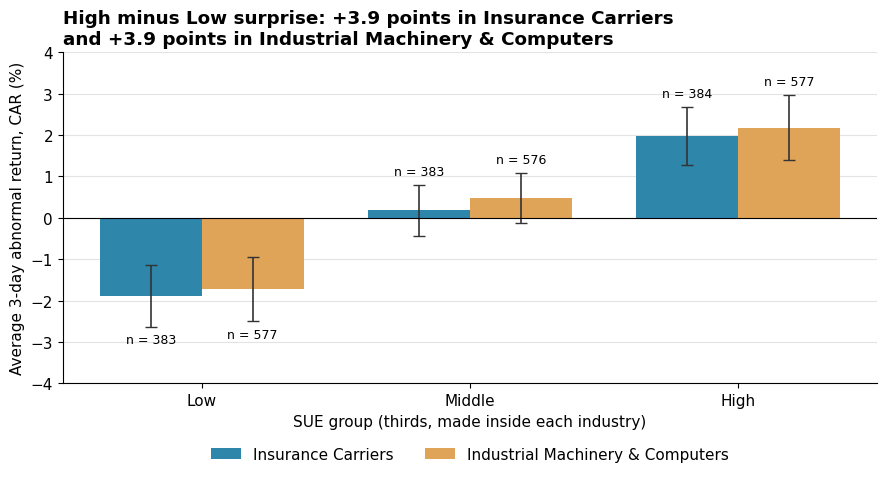

In [32]:
# ===== 2b. Figure 1: the two industries side by side (a plain function, because it uses two objects) =====
plt.rcParams.update({
    "font.size": 11, "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#E3E3E3",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})

def plot_compare(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(LABELS))
    width = 0.38
    for j, ind in enumerate(industries):
        t = ind.group_table()
        mean = t["mean"] * 100
        ci   = t["ci95"] * 100
        pos  = x + (j - 0.5) * width
        ax.bar(pos, mean, width, yerr=ci, capsize=4, color=colors[j], label=ind.name,
               error_kw={"elinewidth": 1.2, "ecolor": "#333333"})
        for i, g in enumerate(LABELS):                                  # n on each bar
            top = mean[g] + ci[g] if mean[g] >= 0 else mean[g] - ci[g]
            ax.annotate(f"n = {t.loc[g, 'n']}", (pos[i], top),
                        xytext=(0, 5 if mean[g] >= 0 else -5), textcoords="offset points",
                        ha="center", va="bottom" if mean[g] >= 0 else "top", fontsize=9)
    gaps = [ind.ttest()["High - Low (pp)"] for ind in industries]
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, LABELS)
    ax.set_ylim(-4, 4)                                                  # the same y-axis for both industries
    ax.set_title(f"High minus Low surprise: {gaps[0]:+.1f} points in {industries[0].name}\n"
                 f"and {gaps[1]:+.1f} points in {industries[1].name}", loc="left", fontweight="bold")
    ax.set_xlabel("SUE group (thirds, made inside each industry)")
    ax.set_ylabel("Average 3-day abnormal return, CAR (%)")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_compare([mine, peer], colors=[COLOR_MINE, COLOR_PEER], file_name="figures/figure1_car_by_group.png")

In [33]:
# ===== 3. Welch t-test: High vs Low, for each industry =====
for ind in [mine, peer]:
    r = ind.ttest()
    print(f"{ind.name}: High - Low = {r['High - Low (pp)']:.2f} percentage points | t = {r['t']:.2f} | p = {r['p (t-test)']:.4f}")

Insurance Carriers: High - Low = 3.86 percentage points | t = 7.38 | p = 0.0000
Industrial Machinery & Computers: High - Low = 3.90 percentage points | t = 6.94 | p = 0.0000


In [34]:
# ===== 4a. Regression CAR = a + b * SUE: original and winsorized (1% / 99%), for each industry =====
for ind in [mine, peer]:
    model   = smf.ols("car ~ sue",   data=ind.events).fit()
    model_w = smf.ols("car_w ~ sue", data=ind.events).fit()
    print(ind.name)
    print(model.summary())
    results = pd.DataFrame({
        "b (slope)":    [model.params["sue"],  model_w.params["sue"]],
        "p-value of b": [model.pvalues["sue"], model_w.pvalues["sue"]],
        "R-squared":    [model.rsquared,       model_w.rsquared],
        "n":            [int(model.nobs),      int(model_w.nobs)],
    }, index=["original", "winsorized 1%/99%"]).round(4)
    display(results)

Insurance Carriers
                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.020
Model:                            OLS   Adj. R-squared:                  0.020
Method:                 Least Squares   F-statistic:                     23.93
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           1.14e-06
Time:                        15:27:17   Log-Likelihood:                 1426.0
No. Observations:                1150   AIC:                            -2848.
Df Residuals:                    1148   BIC:                            -2838.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0007      0.002 

,b (slope),p-value of b,R-squared,n
original,0.1082,0.0,0.0204,1150
winsorized 1%/99%,0.1091,0.0,0.0244,1150


Industrial Machinery & Computers
                            OLS Regression Results                            
Dep. Variable:                    car   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     27.62
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           1.66e-07
Time:                        15:27:17   Log-Likelihood:                 1719.2
No. Observations:                1730   AIC:                            -3434.
Df Residuals:                    1728   BIC:                            -3423.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.00

,b (slope),p-value of b,R-squared,n
original,0.2150,0.0,0.0157,1730
winsorized 1%/99%,0.1879,0.0,0.0137,1730


In [35]:
for ind in [mine, peer]:
    ev = ind.events
    ev["fyearq"] = ev["fyearq"].astype(int)          # nullable Int64 -> plain int (as in w12)
    cl = dict(cov_type="cluster", cov_kwds={"groups": ev["gvkey"]})
    m1 = smf.ols("car_w ~ sue", data=ev).fit(**cl)
    m2 = smf.ols("car_w ~ sue + C(fyearq)", data=ev).fit(**cl)
    m3 = smf.ols("car_w ~ sue * loss + C(fyearq)", data=ev).fit(**cl)
    print(ind.name)
    print(summary_col([m1, m2, m3], stars=True,
                      model_names=["(1) base", "(2) year FE", "(3) year FE + loss"],
                      regressor_order=["sue", "loss", "sue:loss"], drop_omitted=True,
                      info_dict={"R2": lambda m: f"{m.rsquared:.3f}", "n": lambda m: f"{int(m.nobs)}"}))
    print()

Insurance Carriers

                (1) base (2) year FE (3) year FE + loss
-------------------------------------------------------
sue            0.1091*** 0.1099***   0.1093***         
               (0.0285)  (0.0289)    (0.0314)          
loss                                 -0.0152*          
                                     (0.0089)          
sue:loss                             -0.0256           
                                     (0.0573)          
R-squared      0.0244    0.0248      0.0328            
R-squared Adj. 0.0236    0.0205      0.0269            
R2             0.024     0.025       0.033             
n              1150      1150        1150              
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01

Industrial Machinery & Computers

                (1) base (2) year FE (3) year FE + loss
-------------------------------------------------------
sue            0.1879*** 0.1906***   0.4310***         
               (0.0635)  (0.0639)    (0.0987) 

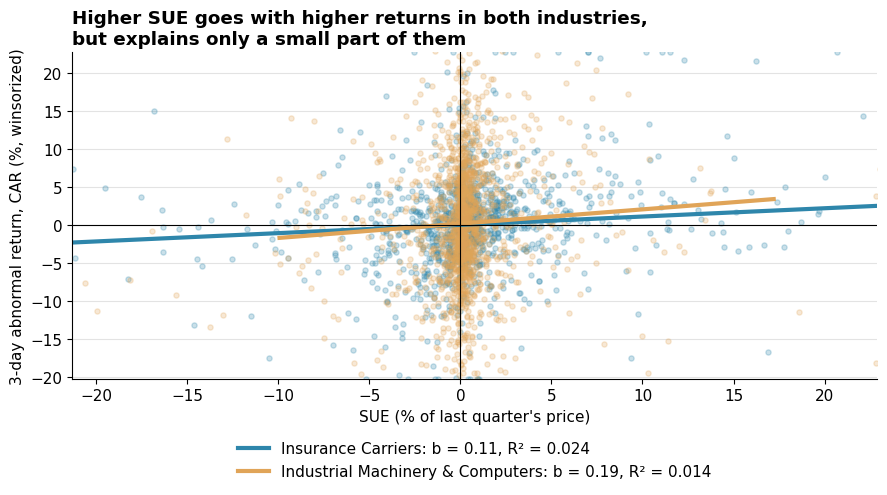

In [36]:
# ===== 4c. Figure 2: SUE and CAR, one color per industry, with each regression line =====
def plot_scatter(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(9, 5.2))
    r2s = []
    for j, ind in enumerate(industries):
        ev = ind.events
        m  = smf.ols("car_w ~ sue", data=ev).fit()
        r2s.append(m.rsquared)
        ax.scatter(ev["sue"] * 100, ev["car_w"] * 100, s=14, alpha=0.25, color=colors[j])
        x_line = np.linspace(ev["sue"].quantile(0.01), ev["sue"].quantile(0.99), 100)
        y_line = m.params["Intercept"] + m.params["sue"] * x_line
        ax.plot(x_line * 100, y_line * 100, color=colors[j], linewidth=3,
                label=f"{ind.name}: b = {m.params['sue']:.2f}, R² = {m.rsquared:.3f}")
    # Zoom in on the middle 98% of the points; the lines are still estimated on all announcements.
    all_sue = pd.concat([ind.events["sue"] for ind in industries])
    all_car = pd.concat([ind.events["car_w"] for ind in industries])
    ax.set_xlim(all_sue.quantile(0.01) * 100, all_sue.quantile(0.99) * 100)
    ax.set_ylim(all_car.quantile(0.01) * 100, all_car.quantile(0.99) * 100)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title("Higher SUE goes with higher returns in both industries,\nbut explains only a small part of them",
                 loc="left", fontweight="bold")
    ax.set_xlabel("SUE (% of last quarter's price)")
    ax.set_ylabel("3-day abnormal return, CAR (%, winsorized)")
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_scatter([mine, peer], colors=[COLOR_MINE, COLOR_PEER], file_name="figures/figure2_scatter.png")

In [37]:
# ===== 5a. The comparison table: one row per industry =====
compare = pd.DataFrame([mine.summary(), peer.summary()]).set_index("industry")
compare.round(4)

,SIC,n,companies,High - Low (pp),t,p (t-test),b,p (b),R2
industry,,,,,,,,,
Insurance Carriers,63,1150,88,3.8610,7.3845,0.0,0.1091,0.0,0.0244
Industrial Machinery & Computers,35,1730,131,3.9034,6.9412,0.0,0.1879,0.0,0.0137


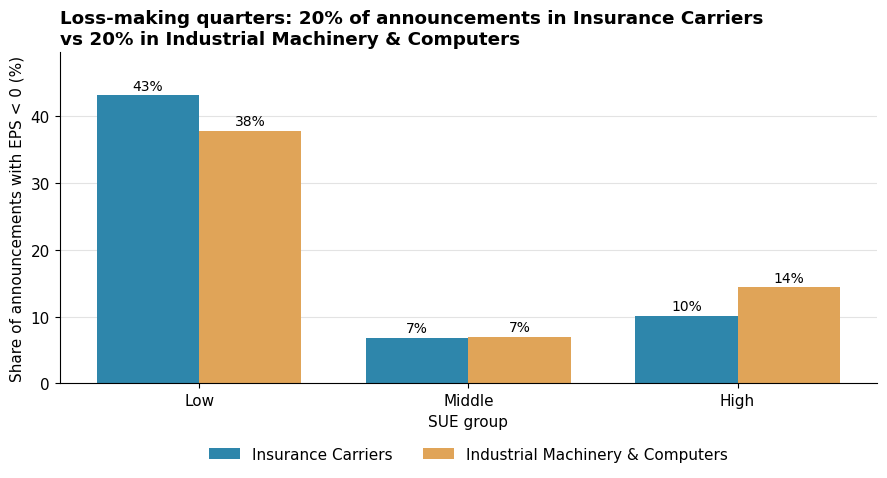

In [38]:
# ===== 5b. Figure 3: share of loss-making announcements in each SUE group =====
def plot_loss(industries, colors, file_name):
    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(LABELS))
    width = 0.38
    for j, ind in enumerate(industries):
        share = ind.loss_share()
        pos = x + (j - 0.5) * width
        ax.bar(pos, share, width, color=colors[j], label=ind.name)
        for i, g in enumerate(LABELS):
            ax.annotate(f"{share[g]:.0f}%", (pos[i], share[g]), xytext=(0, 4),
                        textcoords="offset points", ha="center", fontsize=10)
    overall = [ind.events["loss"].mean() * 100 for ind in industries]
    ax.set_xticks(x, LABELS)
    ax.set_title(f"Loss-making quarters: {overall[0]:.0f}% of announcements in {industries[0].name}\n"
                 f"vs {overall[1]:.0f}% in {industries[1].name}", loc="left", fontweight="bold")
    ax.set_xlabel("SUE group")
    ax.set_ylabel("Share of announcements with EPS < 0 (%)")
    ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    ax.margins(y=0.15)
    plt.tight_layout()
    fig.savefig(file_name, dpi=200)
    plt.show()

plot_loss([mine, peer], colors=[COLOR_MINE, COLOR_PEER], file_name="figures/figure3_loss_share.png")

/home/clark/mculhane
